# Riesgo de inundaciones en el Chocó
## Modelo del semáforo de riesgo (versión final)

**Qué responde el modelo:** para una estación de nivel del río, a una hora dada: **¿el río llegará a nivel rojo en las próximas 24 horas?**

El nivel de cada río se compara con su propia historia mediante **percentiles** (el percentil 95 es un nivel que solo se supera 1 de cada 20 horas):

| Color | El nivel máximo de las próximas 24 horas será... |
|---|---|
| Verde | menor que el percentil 75 de la historia de la estación |
| Amarillo | entre el percentil 75 y el 95 |
| Rojo | el percentil 95 o más: posible crecida |

**Cómo funciona:** un bosque aleatorio lee el nivel del río y la lluvia de las horas y días anteriores, y calcula la probabilidad de cada color. Si la probabilidad de rojo llega al umbral definido, el semáforo marca rojo.
El modelo se compara con dos **reglas simples** que no aprenden nada: copiar el color del nivel de hoy, y copiar el color del máximo de las últimas 24 horas.

**Por qué por hora y no por día:** los ríos de esta zona suben y bajan en pocas horas. Con un promedio diario se pierde justamente la información que anticipa una crecida.

**Datos:** `datos/datos_horarios.csv`, generado por `preparar_datos.py` a partir de los archivos de datos.gov.co (nivel y lluvia, 2022 a 2026).

**Lo que deja este notebook:** `modelo/modelo_semaforo_v3.joblib` y `modelo/metadatos_modelo.json`.

## 1. Librerías y configuración

In [11]:
import json
import warnings
from datetime import datetime
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")

AZUL_PROFUNDO = "#0B3C5D"
GRIS = "#7F8C8D"
NARANJA = "#E67E22"
COLORES_SEMAFORO = {"Verde": "#7BC67E", "Amarillo": "#F7D154", "Rojo": "#E06666"}
ORDEN = ["Verde", "Amarillo", "Rojo"]

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
plt.rcParams["axes.titleweight"] = "bold"

SEMILLA = 42
HORIZONTE_H = 24           # se predice el nivel máximo de las próximas 24 horas
UMBRAL_AMARILLO = 75       # percentil desde el que el semáforo es amarillo
UMBRAL_ROJO = 95           # percentil desde el que el semáforo es rojo
UMBRAL_PROB_ROJO = 0.40    # probabilidad de rojo desde la cual se avisa rojo (ver sección 4.3)
PASO_HORAS = 3             # se usa una hora de cada 3 como momento de predicción (horas seguidas son casi iguales)
MAX_HORAS_SIN_DATO = 48    # una estación sin datos en más de 48 horas no entra al semáforo
VERSION_MODELO = "v3"

RUTA_DATOS = Path("datos/datos_horarios.csv")
CARPETA_MODELO = Path("modelo")
CARPETA_MODELO.mkdir(exist_ok=True)

GRILLA = np.linspace(0, 100, 1001)    # los percentiles se guardan como 1001 puntos por estación

## 2. Los datos y qué estaciones sirven

Cada fila es una hora de una estación de nivel del río, con la lluvia promediada de los pluviómetros cercanos (a menos de 25 km).
Se revisó la calidad de cada estación y **solo entran al modelo las que tienen historia larga y coherente**. Las demás se quedan fuera por una razón concreta, que se muestra en la tabla.

In [12]:
datos_todas = pd.read_csv(RUTA_DATOS, parse_dates=["fecha_hora"], dtype={"estacion": str})

MOTIVO_EXCLUSION = {
    "0011047040": "Estación anterior de Quibdó: sus datos terminan en septiembre de 2024",
    "1111700230": "Solo 1 año de datos y su nivel cambió de rango en 2026; la regla del máximo de 24 h lo predice mejor que el modelo",
    "0054017040": "Solo 1 año de datos: muy pocas crecidas para entrenar y validar",
    "0011027070": "Muy pocos datos (17 % de las horas) y 12 % de saltos bruscos de una hora a otra",
    "0054057010": "Muy pocos datos (15 % de las horas) y casi sin lluvia medida",
}
ESTACIONES = ["0011047010", "0011047020", "0011027030", "0054027050"]

resumen = []
for est, g in datos_todas.groupby("estacion"):
    con_nivel = g.dropna(subset=["nivel_m"])
    resumen.append({
        "Estación": est, "Municipio": g["municipio"].iloc[0], "Nombre": g["nombre_estacion"].iloc[0],
        "Desde": g["fecha_hora"].min().date(), "Hasta": g["fecha_hora"].max().date(),
        "Horas con nivel": len(con_nivel), "% de horas con nivel": round(len(con_nivel) / len(g) * 100),
        "Usa el modelo": "Sí" if est in ESTACIONES else "No", "Motivo": MOTIVO_EXCLUSION.get(est, "")})
display(pd.DataFrame(resumen).sort_values("Horas con nivel", ascending=False).reset_index(drop=True))

datos = datos_todas[datos_todas["estacion"].isin(ESTACIONES)].sort_values(["estacion", "fecha_hora"]).reset_index(drop=True)
INFO_ESTACIONES = datos.drop_duplicates("estacion").set_index("estacion")[["municipio", "nombre_estacion"]].loc[ESTACIONES]
print("Estaciones del modelo:", len(ESTACIONES), "| horas con nivel:", int(datos["nivel_m"].notna().sum()))
print("Última hora con nivel:", datos.dropna(subset=["nivel_m"])["fecha_hora"].max(),
      "| última hora con lluvia:", datos.dropna(subset=["lluvia_mm"])["fecha_hora"].max())

,Estación,Municipio,Nombre,Desde,Hasta,Horas con nivel,% de horas con nivel,Usa el modelo,Motivo
0,0011047010,QUIBDO,BELEN,2022-01-01,2026-10-24,19586,46,Sí,
1,0011027030,CARMEN DE ATRATO,EL SIETE,2022-03-31,2026-10-24,13949,35,Sí,
2,0054027050,RIO IRO,RIO IRO,2024-06-30,2026-10-24,11073,54,Sí,
3,0011047020,QUIBDO,QUIBDO 0011047020,2025-07-23,2026-07-04,7702,93,Sí,
4,1111700230,CARMEN DEL DARIEN,CURVARADO,2025-05-16,2026-05-04,7430,88,No,Solo 1 año de datos y su nivel cambió de rango...
5,0054017040,TADO,TADO,2025-10-20,2026-10-24,5797,65,No,Solo 1 año de datos: muy pocas crecidas para e...
6,0011027070,LLORO,BORAUDO,2023-07-13,2026-06-13,4280,17,No,Muy pocos datos (17 % de las horas) y 12 % de ...
7,0011047040,QUIBDO,QUIBDO 0011047040,2022-03-31,2024-09-13,3242,15,No,Estación anterior de Quibdó: sus datos termina...
8,0054057010,MEDIO SAN JUAN,NOANAMA ASERRIO,2024-07-05,2026-10-22,3006,15,No,Muy pocos datos (15 % de las horas) y casi sin...


Estaciones del modelo: 4 | horas con nivel: 52310
Última hora con nivel: 2026-10-24 23:00:00 | última hora con lluvia: 2026-07-24 23:00:00


## 3. Preparación de las variables

**Percentil.** El nivel en metros se convierte en un percentil (0 a 100) usando la historia de la estación. La regla de conversión se fija con el periodo de entrenamiento y se guarda en los metadatos.

**Variables de entrada** (todas se conocen en el momento de predecir):

- **Nivel del río:** percentil actual, cuánto cambió en 1, 3, 6, 12, 24 y 48 horas, y máximo, mínimo y promedio de los últimos 1, 3 y 7 días.
- **Cuánto sube el río** en metros por hora y cuánto se aleja de su nivel normal de los últimos 30 y 90 días (esto corrige los cambios lentos del nivel de la estación).
- **Lluvia:** acumulada en 1, 3, 6, 12, 24, 48 y 72 horas y en 7, 14 y 30 días, y la mayor lluvia de una hora en el último día.
- **Hora del día y mes del año**, como ciclos.
- **Estación**.

**Qué se predice:** el color según el nivel máximo de las próximas 24 horas.

In [13]:
def referencia_desde(niveles):
    """Regla para convertir un nivel (m) en percentil: 1001 niveles equivalentes a los percentiles 0, 0.1, ..., 100."""
    return np.quantile(np.asarray(niveles, dtype=float), GRILLA / 100)


def a_percentil(nivel, referencia):
    return np.interp(np.asarray(nivel, dtype=float), referencia, GRILLA)


def escala_de(niveles):
    """Rango intercuartílico de la estación: sirve para comparar cambios de nivel entre ríos."""
    return max(float(np.quantile(niveles, 0.75) - np.quantile(niveles, 0.25)), 1e-6)


def color_de_percentil(percentil):
    """0 verde, 1 amarillo, 2 rojo."""
    return np.where(percentil >= UMBRAL_ROJO, 2, np.where(percentil >= UMBRAL_AMARILLO, 1, 0))


VARIABLES = (["nivel_percentil"] + [f"cambio_{h}h" for h in (1, 3, 6, 12, 24, 48)]
             + ["max_24h", "max_72h", "max_7d", "media_7d", "min_24h"]
             + [f"subida_{h}h" for h in (1, 3, 6, 12, 24)] + ["anomalia_30d", "anomalia_90d", "rango_24h"]
             + [f"lluvia_{h}h" for h in (1, 3, 6, 12, 24, 48, 72, 168, 336, 720)] + ["lluvia_max_1h_24h"]
             + ["hora_sin", "hora_cos", "mes_sin", "mes_cos"])


def columna_estacion(codigo):
    return "est_" + codigo


COLUMNAS_X = VARIABLES + [columna_estacion(e) for e in ESTACIONES]


def variables_estacion(tabla, referencia, escala):
    """Variables de una estación para cada hora. La tabla debe traer fecha_hora, nivel_m y lluvia_mm."""
    t = tabla.set_index("fecha_hora").sort_index()
    t = t.reindex(pd.date_range(t.index.min(), t.index.max(), freq="h"))      # una fila por hora, sin saltos
    nivel, lluvia = t["nivel_m"], t["lluvia_mm"]
    p = pd.Series(a_percentil(nivel, referencia), index=t.index)
    f = pd.DataFrame(index=t.index)
    f["nivel_percentil"] = p
    for h in (1, 3, 6, 12, 24, 48):
        f[f"cambio_{h}h"] = p - p.shift(h)
    f["max_24h"] = p.rolling(24, min_periods=12).max()
    f["max_72h"] = p.rolling(72, min_periods=36).max()
    f["max_7d"] = p.rolling(168, min_periods=72).max()
    f["media_7d"] = p.rolling(168, min_periods=72).mean()
    f["min_24h"] = p.rolling(24, min_periods=12).min()
    for h in (1, 3, 6, 12, 24):
        f[f"subida_{h}h"] = (nivel - nivel.shift(h)) / escala
    f["anomalia_30d"] = (nivel - nivel.rolling(720, min_periods=240).median()) / escala
    f["anomalia_90d"] = (nivel - nivel.rolling(2160, min_periods=720).median()) / escala
    f["rango_24h"] = (nivel.rolling(24, min_periods=12).max() - nivel.rolling(24, min_periods=12).min()) / escala
    for h in (1, 3, 6, 12, 24, 48, 72, 168, 336, 720):
        f[f"lluvia_{h}h"] = lluvia.rolling(h, min_periods=max(1, h // 2)).sum()
    f["lluvia_max_1h_24h"] = lluvia.rolling(24, min_periods=12).max()
    f["hora_sin"], f["hora_cos"] = np.sin(2 * np.pi * t.index.hour / 24), np.cos(2 * np.pi * t.index.hour / 24)
    f["mes_sin"], f["mes_cos"] = np.sin(2 * np.pi * t.index.month / 12), np.cos(2 * np.pi * t.index.month / 12)
    # Lo que queremos adivinar: el nivel máximo (percentil) de las próximas 24 horas
    f["objetivo_percentil"] = p[::-1].rolling(HORIZONTE_H, min_periods=int(HORIZONTE_H * 0.75)).max()[::-1].shift(-1)
    f["estacion"] = tabla["estacion"].iloc[0]
    return f


def construir_variables(tabla, referencias, escalas):
    t = pd.concat([variables_estacion(g, referencias[e], escalas[e]) for e, g in tabla.groupby("estacion") if e in referencias])
    for e in ESTACIONES:
        t[columna_estacion(e)] = (t["estacion"] == e).astype(int)
    t["color_objetivo"] = color_de_percentil(t["objetivo_percentil"])
    return t


def referencias_y_escalas(tabla):
    refs, esc = {}, {}
    for e, g in tabla.groupby("estacion"):
        niveles = g["nivel_m"].dropna().values
        if len(niveles) >= 100:
            refs[e], esc[e] = referencia_desde(niveles), escala_de(niveles)
    return refs, esc


def crear_modelo():
    return RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=10, class_weight="balanced_subsample",
                                  random_state=SEMILLA, n_jobs=-1)


def probabilidades(modelo, X):
    """Probabilidad de verde, amarillo y rojo (columnas 0, 1 y 2)."""
    return (pd.DataFrame(modelo.predict_proba(X), columns=modelo.classes_, index=X.index)
            .reindex(columns=[0, 1, 2], fill_value=0.0))


def semaforo_desde(proba, umbral_rojo=None):
    umbral = UMBRAL_PROB_ROJO if umbral_rojo is None else umbral_rojo
    return np.where(proba[2] >= umbral, 2, np.where(proba[1] >= proba[0], 1, 0))

## 4. Validación por bloques de tiempo

Se divide el tiempo en 6 bloques y, para cada uno de los últimos cuatro, se **entrena con todo lo anterior y se prueba con ese bloque**. En cada vuelta la regla del percentil y las escalas se calculan solo con el pasado.
No se mezclan horas al azar: el modelo vería horas casi idénticas a la que debe adivinar y haría trampa. Además se deja un margen de 24 horas entre el entrenamiento y la prueba.

In [14]:
horas_con_nivel = np.sort(datos.loc[datos["nivel_m"].notna(), "fecha_hora"].unique())
cortes = [pd.Timestamp(horas_con_nivel[int(len(horas_con_nivel) * q)]) for q in (2 / 6, 3 / 6, 4 / 6, 5 / 6)]
cortes.append(datos["fecha_hora"].max() + pd.Timedelta(hours=1))
print("Bloques de prueba:", [f"{cortes[i].date()} a {cortes[i + 1].date()}" for i in range(4)])

evaluaciones = []
for k in range(4):
    inicio, fin = cortes[k], cortes[k + 1]
    refs, escalas = referencias_y_escalas(datos[datos["fecha_hora"] < inicio])
    t = construir_variables(datos, refs, escalas).dropna(subset=["nivel_percentil", "objetivo_percentil"])
    t = t[t.index.hour % PASO_HORAS == 0]
    entrenamiento = t[t.index < inicio - pd.Timedelta(hours=HORIZONTE_H)]
    prueba = t[(t.index >= inicio) & (t.index < fin)]
    if len(prueba) == 0 or len(entrenamiento) < 200:
        continue
    modelo_k = crear_modelo().fit(entrenamiento[COLUMNAS_X], entrenamiento["color_objetivo"])
    proba = probabilidades(modelo_k, prueba[COLUMNAS_X])
    evaluaciones.append(pd.DataFrame({
        "bloque": k + 1, "estacion": prueba["estacion"].values, "hora": prueba.index, "real": prueba["color_objetivo"].values,
        "Regla: nivel de hoy": color_de_percentil(prueba["nivel_percentil"].values),
        "Regla: máximo de 24 h": color_de_percentil(prueba["max_24h"].values),
        "prob_verde": proba[0].values, "prob_amarillo": proba[1].values, "prob_rojo": proba[2].values}))

evaluaciones = pd.concat(evaluaciones, ignore_index=True)
evaluaciones["Bosque aleatorio"] = semaforo_desde(evaluaciones[["prob_verde", "prob_amarillo", "prob_rojo"]].set_axis([0, 1, 2], axis=1))
print("Momentos evaluados:", len(evaluaciones), "| con rojo en las próximas 24 h:", int((evaluaciones["real"] == 2).sum()),
      "| con amarillo:", int((evaluaciones["real"] == 1).sum()))

Bloques de prueba: ['2023-08-03 a 2024-10-30', '2024-10-30 a 2025-09-26', '2025-09-26 a 2026-03-29', '2026-03-29 a 2026-10-25']
Momentos evaluados: 11250 | con rojo en las próximas 24 h: 1225 | con amarillo: 2508


### 4.1 Resultados

- **Color acertado:** porcentaje de momentos en que el semáforo coincidió con el real.
- **Rojos detectados:** de los momentos que de verdad tuvieron rojo en las 24 horas siguientes, cuántos avisó el semáforo.
- **Alertas rojas correctas:** de las veces que avisó rojo, cuántas lo eran.
- **F1 del rojo:** equilibrio entre las dos anteriores (1 es perfecto).

In [15]:
def medir(real, predicho):
    real, predicho = np.asarray(real), np.asarray(predicho)
    r, p = real == 2, predicho == 2
    return {
        "Color acertado": accuracy_score(real, predicho),
        "Rojos detectados": recall_score(r, p, zero_division=0),
        "Alertas rojas correctas": precision_score(r, p, zero_division=0),
        "F1 del rojo": f1_score(r, p, zero_division=0),
        "Rojos no detectados": int((r & ~p).sum()),
        "Falsas alarmas": int((~r & p).sum()),
    }


MODELOS = ["Regla: nivel de hoy", "Regla: máximo de 24 h", "Bosque aleatorio"]
resultado_total = pd.DataFrame({m: medir(evaluaciones["real"], evaluaciones[m]) for m in MODELOS}).T
display(resultado_total.round(2))

por_bloque = []
for bloque, grupo in evaluaciones.groupby("bloque"):
    for m in MODELOS:
        por_bloque.append({"Bloque": bloque, "Modelo": m, "Momentos": len(grupo), "Rojos": int((grupo["real"] == 2).sum()),
                           "Rojos detectados": medir(grupo["real"], grupo[m])["Rojos detectados"],
                           "F1 del rojo": medir(grupo["real"], grupo[m])["F1 del rojo"]})
display(pd.DataFrame(por_bloque).round(2))

,Color acertado,Rojos detectados,Alertas rojas correctas,F1 del rojo,Rojos no detectados,Falsas alarmas
Regla: nivel de hoy,0.77,0.37,0.96,0.54,771.0,18.0
Regla: máximo de 24 h,0.70,0.53,0.53,0.53,581.0,576.0
Bosque aleatorio,0.74,0.50,0.73,0.60,610.0,222.0


,Bloque,Modelo,Momentos,Rojos,Rojos detectados,F1 del rojo
0,1,Regla: nivel de hoy,1160,94,0.36,0.53
1,1,Regla: máximo de 24 h,1160,94,0.64,0.65
2,1,Bosque aleatorio,1160,94,0.57,0.62
3,2,Regla: nivel de hoy,1266,73,0.18,0.30
4,2,Regla: máximo de 24 h,1266,73,0.38,0.37
5,2,Bosque aleatorio,1266,73,0.47,0.47
6,3,Regla: nivel de hoy,4480,817,0.45,0.62
7,3,Regla: máximo de 24 h,4480,817,0.59,0.59
8,3,Bosque aleatorio,4480,817,0.58,0.68
9,4,Regla: nivel de hoy,4344,241,0.15,0.26


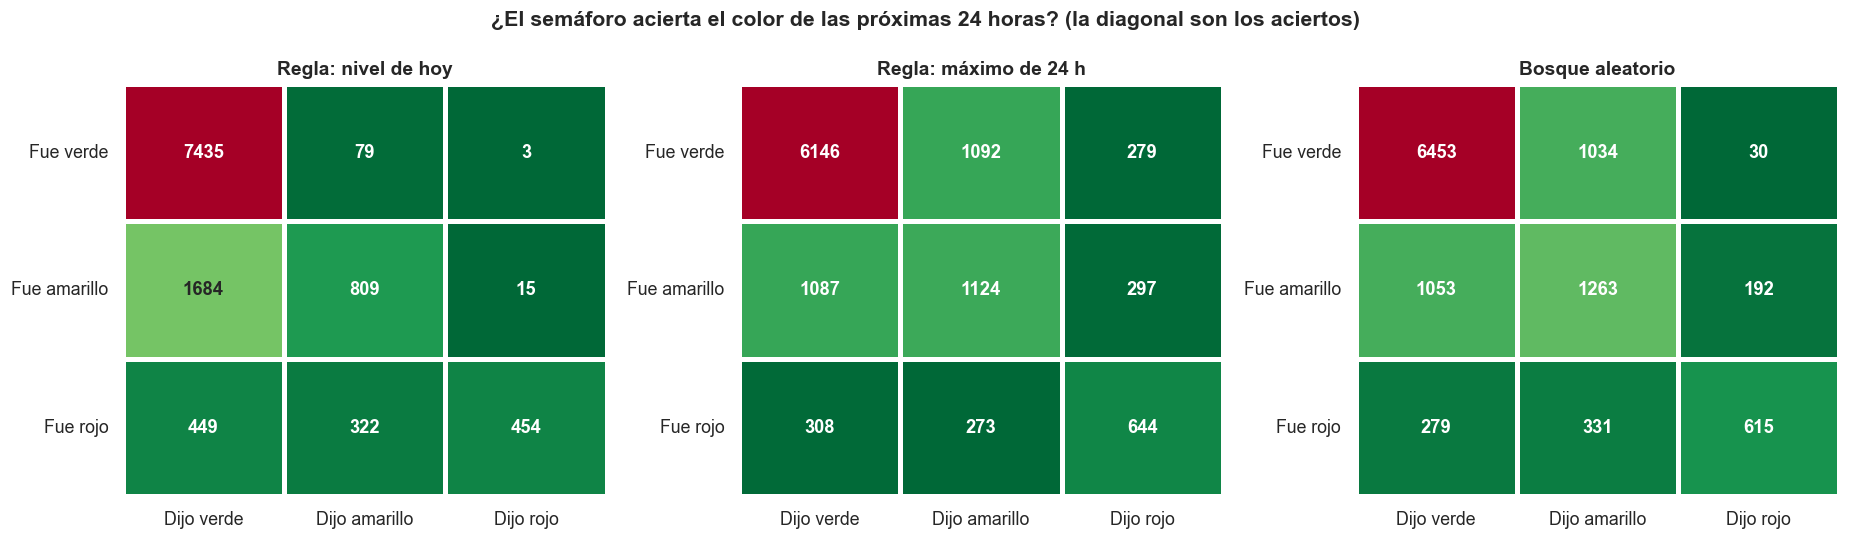

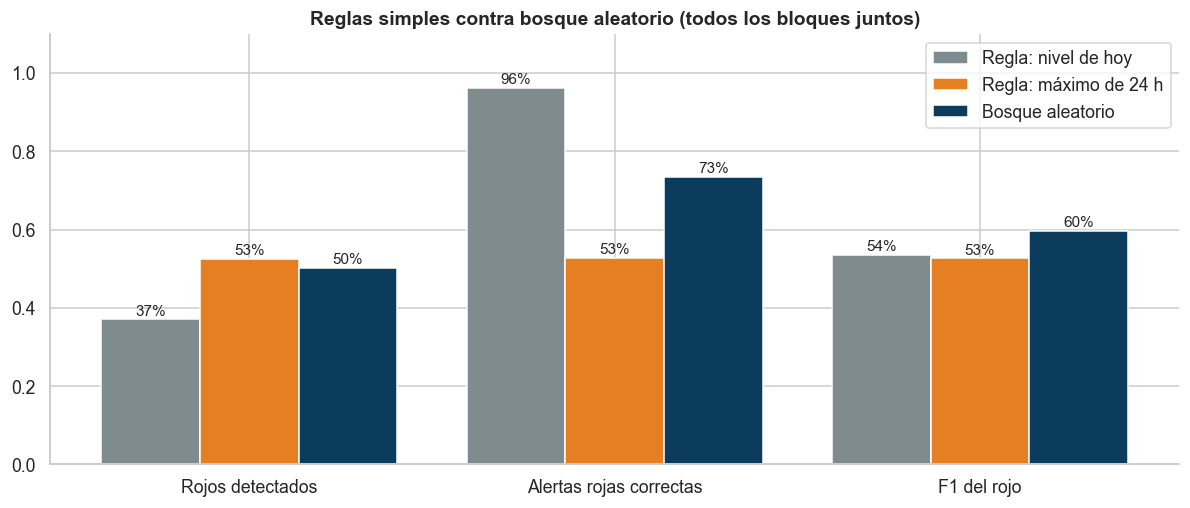

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, modelo_nombre in zip(axes, MODELOS):
    matriz = confusion_matrix(evaluaciones["real"], evaluaciones[modelo_nombre], labels=[0, 1, 2])
    sns.heatmap(matriz, annot=True, fmt="d", cmap="RdYlGn_r", cbar=False, linewidths=2, linecolor="white", ax=ax,
                annot_kws={"fontsize": 12, "fontweight": "bold"},
                xticklabels=[f"Dijo {o.lower()}" for o in ORDEN], yticklabels=[f"Fue {o.lower()}" for o in ORDEN])
    ax.set_title(modelo_nombre)
    ax.tick_params(axis="y", rotation=0)
fig.suptitle("¿El semáforo acierta el color de las próximas 24 horas? (la diagonal son los aciertos)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

metricas = ["Rojos detectados", "Alertas rojas correctas", "F1 del rojo"]
fig, ax = plt.subplots(figsize=(11, 4.8))
x = np.arange(len(metricas))
for i, (nombre, color) in enumerate(zip(MODELOS, [GRIS, NARANJA, AZUL_PROFUNDO])):
    barras = ax.bar(x + (i - 1) * 0.27, resultado_total.loc[nombre, metricas].astype(float).values, width=0.27, color=color, label=nombre)
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01, f"{b.get_height():.0%}", ha="center", fontsize=10)
ax.set_xticks(x)
ax.set_xticklabels(metricas)
ax.set_ylim(0, 1.1)
ax.set_title("Reglas simples contra bosque aleatorio (todos los bloques juntos)")
ax.legend()
plt.tight_layout()
plt.show()

### 4.2 Resultado por estación

El modelo no rinde igual en todos los ríos: los que tienen más historia (Quibdó) se predicen mejor.

In [17]:
filas = []
for est, g in evaluaciones.groupby("estacion"):
    fila = {"Municipio": INFO_ESTACIONES.loc[est, "municipio"], "Estación": INFO_ESTACIONES.loc[est, "nombre_estacion"],
            "Momentos": len(g), "Con rojo": int((g["real"] == 2).sum())}
    for m in MODELOS:
        fila[f"F1 {m}"] = medir(g["real"], g[m])["F1 del rojo"]
    filas.append(fila)
display(pd.DataFrame(filas).round(2))

,Municipio,Estación,Momentos,Con rojo,F1 Regla: nivel de hoy,F1 Regla: máximo de 24 h,F1 Bosque aleatorio
0,CARMEN DE ATRATO,EL SIETE,2467,151,0.17,0.34,0.31
1,QUIBDO,BELEN,3882,379,0.70,0.71,0.77
2,QUIBDO,QUIBDO 0011047020,2076,352,0.67,0.65,0.72
3,RIO IRO,RIO IRO,2825,343,0.27,0.28,0.36


### 4.3 ¿Qué umbral de probabilidad conviene?

Un umbral bajo avisa más rojos pero da más falsas alarmas; uno alto hace lo contrario. El valor por defecto (0.40) es el que mejor equilibra las dos cosas en esta validación.
Si lo importante es **no perder ningún rojo**, se puede bajar `UMBRAL_PROB_ROJO` y aceptar más falsas alarmas.

In [18]:
filas = []
for umbral in [0.2, 0.3, 0.4, 0.5, 0.6]:
    predicho = np.where(evaluaciones["prob_rojo"] >= umbral, 2, 0)
    m = medir(evaluaciones["real"], predicho)
    filas.append({"Umbral": umbral, "Rojos detectados": m["Rojos detectados"], "Alertas rojas correctas": m["Alertas rojas correctas"],
                  "F1 del rojo": m["F1 del rojo"], "Rojos no detectados": m["Rojos no detectados"], "Falsas alarmas": m["Falsas alarmas"]})
for regla in MODELOS[:2]:
    m = medir(evaluaciones["real"], evaluaciones[regla])
    filas.append({"Umbral": regla, **{k: m[k] for k in ["Rojos detectados", "Alertas rojas correctas", "F1 del rojo", "Rojos no detectados", "Falsas alarmas"]}})
display(pd.DataFrame(filas).set_index("Umbral").round(2))

,Rojos detectados,Alertas rojas correctas,F1 del rojo,Rojos no detectados,Falsas alarmas
Umbral,,,,,
0.2,0.72,0.34,0.46,338,1739
0.3,0.59,0.54,0.56,508,605
0.4,0.50,0.73,0.60,610,222
0.5,0.45,0.85,0.59,676,100
0.6,0.41,0.92,0.56,727,41
Regla: nivel de hoy,0.37,0.96,0.54,771,18
Regla: máximo de 24 h,0.53,0.53,0.53,581,576


### 4.4 ¿Anticipa los rojos que todavía no empezaron?

Lo más difícil (y lo más útil) es avisar un rojo **cuando el río aún no está en rojo**. La regla "nivel de hoy" nunca lo logra; aquí se mide qué tanto lo hace el modelo.

In [19]:
hoy_rojo = evaluaciones["Regla: nivel de hoy"] == 2
rojo_real = evaluaciones["real"] == 2
filas = []
for nombre, mascara in [("El río ya está en rojo", hoy_rojo & rojo_real), ("El río AÚN NO está en rojo y llegará a rojo", ~hoy_rojo & rojo_real)]:
    fila = {"Situación": nombre, "Momentos": int(mascara.sum())}
    for m in MODELOS:
        fila[f"Avisados: {m}"] = int(((evaluaciones[m] == 2) & mascara).sum())
    filas.append(fila)
display(pd.DataFrame(filas).set_index("Situación"))

,Momentos,Avisados: Regla: nivel de hoy,Avisados: Regla: máximo de 24 h,Avisados: Bosque aleatorio
Situación,,,,
El río ya está en rojo,454,454,446,454
El río AÚN NO está en rojo y llegará a rojo,771,0,198,161


## 5. Modelo final

Se entrena con **todos** los datos disponibles. La regla del percentil y las escalas de cada estación se fijan con todo el historial y se guardan: al predecir datos nuevos no se vuelven a calcular.

Momentos de entrenamiento: 15542
color_objetivo  Verde  Amarillo  Rojo
momentos         8573      4842  2127


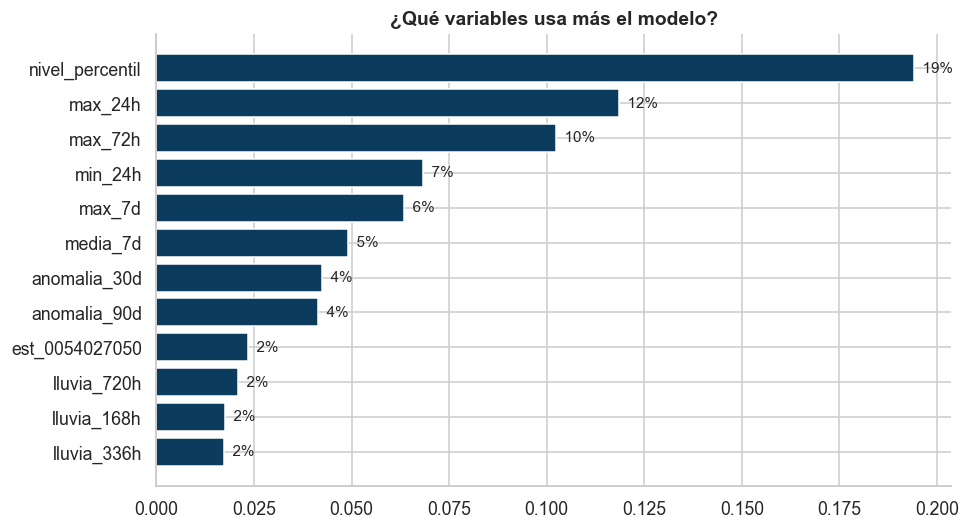

In [20]:
referencias, escalas = referencias_y_escalas(datos)
tabla_final = construir_variables(datos, referencias, escalas).dropna(subset=["nivel_percentil", "objetivo_percentil"])
entrenamiento_final = tabla_final[tabla_final.index.hour % PASO_HORAS == 0]
modelo_final = crear_modelo().fit(entrenamiento_final[COLUMNAS_X], entrenamiento_final["color_objetivo"])

print("Momentos de entrenamiento:", len(entrenamiento_final))
print(entrenamiento_final["color_objetivo"].map(dict(enumerate(ORDEN))).value_counts().to_frame("momentos").T.to_string())

importancia = pd.Series(modelo_final.feature_importances_, index=COLUMNAS_X).sort_values().tail(12)
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(importancia.index, importancia.values, color=AZUL_PROFUNDO)
for y, v in enumerate(importancia.values):
    ax.text(v, y, f"  {v:.0%}", va="center", fontsize=10)
ax.set_title("¿Qué variables usa más el modelo?")
plt.tight_layout()
plt.show()

### 5.1 Guardar el modelo y sus metadatos

El archivo de metadatos conserva todo lo necesario para validar archivos nuevos: columnas requeridas, tipos, rangos, estaciones válidas, variables que no deben enviarse, versión, métrica y la regla de conversión a percentil de cada estación.

In [21]:
f1_modelo = float(resultado_total.loc["Bosque aleatorio", "F1 del rojo"])
f1_reglas = {m: round(float(resultado_total.loc[m, "F1 del rojo"]), 3) for m in MODELOS[:2]}

metadatos = {
    "version": VERSION_MODELO,
    "fecha_entrenamiento": datetime.now().isoformat(timespec="seconds"),
    "estado": "activo",
    "algoritmo": "RandomForestClassifier",
    "configuracion": {"n_estimators": 300, "max_depth": 8, "min_samples_leaf": 10, "class_weight": "balanced_subsample",
                      "random_state": SEMILLA, "umbral_probabilidad_rojo": UMBRAL_PROB_ROJO, "horizonte_horas": HORIZONTE_H,
                      "paso_horas_entrenamiento": PASO_HORAS},
    "registros_entrenamiento": int(len(entrenamiento_final)),
    "periodo_datos": [str(datos["fecha_hora"].min()), str(datos["fecha_hora"].max())],
    "variable_objetivo": {"nombre": "color_semaforo_proximas_24h", "tipo": "categorica", "categorias": ORDEN,
                          "descripcion": "Color según el nivel máximo (percentil) de las próximas 24 horas",
                          "umbrales_percentil": {"amarillo": UMBRAL_AMARILLO, "rojo": UMBRAL_ROJO}},
    "metrica_principal": {"nombre": "F1 del rojo (validación por bloques de tiempo)", "valor_modelo": round(f1_modelo, 3),
                          "valor_reglas_simples": f1_reglas},
    "metricas_validacion": resultado_total.round(3).to_dict(orient="index"),
    "entrada": {
        "descripcion": "Tabla horaria por estación. Para predecir hace falta al menos 7 días (168 horas) de historia anteriores a la hora de predicción; lo ideal son 30 días.",
        "columnas": [
            {"nombre": "estacion", "tipo": "categorica", "admite_faltantes": False, "categorias_validas": ESTACIONES,
             "categoria_desconocida": "rechazar el archivo"},
            {"nombre": "fecha_hora", "tipo": "fecha y hora", "admite_faltantes": False, "frecuencia": "horaria (las horas faltantes se tratan como dato faltante)"},
            {"nombre": "nivel_m", "tipo": "numerico", "admite_faltantes": True, "rango": "mayor que 0 y dentro de 10 rangos intercuartílicos de la estación",
             "nota": "la hora de predicción debe tener nivel"},
            {"nombre": "lluvia_mm", "tipo": "numerico", "admite_faltantes": True, "rango": [0, 500],
             "descripcion": "lluvia de la hora, promedio de los pluviómetros a menos de 25 km"},
        ],
    },
    "variables_modelo": COLUMNAS_X,
    "variables_excluidas": ["municipio", "nombre_estacion", "n_pluviometros", "objetivo_percentil", "color_objetivo"],
    "estaciones": {e: {"municipio": INFO_ESTACIONES.loc[e, "municipio"], "nombre": INFO_ESTACIONES.loc[e, "nombre_estacion"],
                       "escala_nivel_m": round(escalas[e], 4)} for e in ESTACIONES},
    "estaciones_excluidas": {e: motivo for e, motivo in MOTIVO_EXCLUSION.items()},
    "referencia_percentil": {"percentiles": GRILLA.tolist(), "niveles_m": {e: np.round(v, 4).tolist() for e, v in referencias.items()}},
    "archivo_modelo": f"modelo_semaforo_{VERSION_MODELO}.joblib",
}

joblib.dump(modelo_final, CARPETA_MODELO / f"modelo_semaforo_{VERSION_MODELO}.joblib")
with open(CARPETA_MODELO / "metadatos_modelo.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, ensure_ascii=False, indent=1)
print("Guardado en", CARPETA_MODELO.resolve())

Guardado en C:\Users\Lenovo\OneDrive - Fundación Universitaria UNICLARETIANA\Documentos\SISTEMAS INTELIGENTES\proyecto_final\modelo


## 6. Semáforo de las próximas 24 horas

Se carga el modelo **desde los archivos guardados** (como lo hará el sistema web, sin reentrenar) y se calcula el semáforo para cada estación en su última hora con dato de nivel.
Las estaciones con más de 48 horas sin datos no entran al semáforo del municipio.

,Municipio,Estación,Último dato de nivel,Horas sin dato,Días sin lluvia,Nivel actual (percentil),Prob. verde,Prob. amarillo,Prob. rojo,Semáforo próximas 24 h
0,CARMEN DE ATRATO,EL SIETE,2026-10-24 23:00,0,92,21.0,0.34,0.25,0.42,Rojo
1,QUIBDO,BELEN,2026-10-24 23:00,0,92,24.0,0.72,0.21,0.07,Verde
2,QUIBDO,QUIBDO 0011047020,2026-07-04 14:00,2697,112,59.0,0.52,0.35,0.12,Verde
3,RIO IRO,RIO IRO,2026-10-24 23:00,0,92,80.0,0.10,0.70,0.20,Amarillo


,Semáforo del municipio
Municipio,
CARMEN DE ATRATO,Rojo
QUIBDO,Verde
RIO IRO,Amarillo


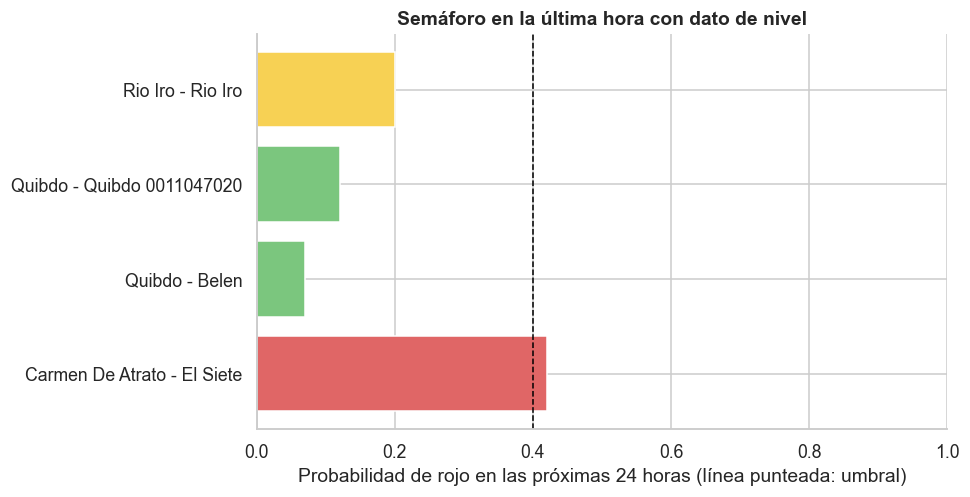

In [22]:
modelo_cargado = joblib.load(CARPETA_MODELO / f"modelo_semaforo_{VERSION_MODELO}.joblib")
with open(CARPETA_MODELO / "metadatos_modelo.json", encoding="utf-8") as f:
    meta = json.load(f)
refs_cargadas = {e: np.array(v) for e, v in meta["referencia_percentil"]["niveles_m"].items()}
escalas_cargadas = {e: v["escala_nivel_m"] for e, v in meta["estaciones"].items()}

t = construir_variables(datos, refs_cargadas, escalas_cargadas)
ultimo = t.dropna(subset=["nivel_percentil"]).groupby("estacion").tail(1)
ultimo = ultimo.assign(hora=ultimo.index).set_index("estacion")
proba = probabilidades(modelo_cargado, ultimo[meta["variables_modelo"]])
color = semaforo_desde(proba, meta["configuracion"]["umbral_probabilidad_rojo"])
assert (color == semaforo_desde(probabilidades(modelo_final, ultimo[COLUMNAS_X]))).all(), "El modelo guardado no da lo mismo que el entrenado"

fin_tabla = datos["fecha_hora"].max()
ultima_lluvia = datos.dropna(subset=["lluvia_mm"]).groupby("estacion")["fecha_hora"].max()
semaforo = pd.DataFrame({
    "Municipio": INFO_ESTACIONES.loc[ultimo.index, "municipio"], "Estación": INFO_ESTACIONES.loc[ultimo.index, "nombre_estacion"],
    "Último dato de nivel": ultimo["hora"].dt.strftime("%Y-%m-%d %H:%M"),
    "Horas sin dato": ((fin_tabla - ultimo["hora"]).dt.total_seconds() / 3600).round(0).astype(int),
    "Días sin lluvia": ((fin_tabla - ultima_lluvia.reindex(ultimo.index)).dt.total_seconds() / 86400).round(0).astype(int),
    "Nivel actual (percentil)": ultimo["nivel_percentil"].round(0),
    "Prob. verde": proba[0].round(2), "Prob. amarillo": proba[1].round(2), "Prob. rojo": proba[2].round(2),
    "Semáforo próximas 24 h": [ORDEN[c] for c in color],
}, index=ultimo.index).sort_values(["Municipio", "Estación"])
display(semaforo.reset_index(drop=True))

al_dia = semaforo[semaforo["Horas sin dato"] <= MAX_HORAS_SIN_DATO]
num = al_dia["Semáforo próximas 24 h"].map({c: i for i, c in enumerate(ORDEN)})
por_municipio = pd.DataFrame({"Semáforo del municipio": num.groupby(al_dia["Municipio"]).max().map(lambda i: ORDEN[i])}
                             ).reindex(sorted(semaforo["Municipio"].unique()))
por_municipio["Semáforo del municipio"] = por_municipio["Semáforo del municipio"].fillna("Sin datos recientes")
display(por_municipio)

fig, ax = plt.subplots(figsize=(9, 0.8 * len(semaforo) + 1.5))
etiquetas = semaforo["Municipio"].str.title() + " - " + semaforo["Estación"].str.title()
ax.barh(etiquetas, semaforo["Prob. rojo"], color=[COLORES_SEMAFORO[c] for c in semaforo["Semáforo próximas 24 h"]])
ax.axvline(meta["configuracion"]["umbral_probabilidad_rojo"], color="black", linestyle="--", linewidth=1)
ax.set_xlim(0, 1)
ax.set_xlabel("Probabilidad de rojo en las próximas 24 horas (línea punteada: umbral)")
ax.set_title("Semáforo en la última hora con dato de nivel")
plt.tight_layout()
plt.show()

## 7. Conclusiones

In [23]:
mejor_regla = max(f1_reglas, key=f1_reglas.get)
n_inicio = int(((~hoy_rojo) & rojo_real).sum())
avisados = int(((evaluaciones["Bosque aleatorio"] == 2) & (~hoy_rojo) & rojo_real).sum())
print(f"Momentos evaluados: {len(evaluaciones)} | con rojo en las próximas 24 h: {int(rojo_real.sum())}")
print(f"F1 del rojo -> bosque aleatorio: {f1_modelo:.2f} | {mejor_regla} (mejor regla simple): {f1_reglas[mejor_regla]:.2f}")
print(f"El bosque detecta {resultado_total.loc['Bosque aleatorio', 'Rojos detectados']:.0%} de los rojos con "
      f"{resultado_total.loc['Bosque aleatorio', 'Alertas rojas correctas']:.0%} de alertas correctas.")
print(f"Rojos que llegan cuando el río aún no está en rojo: {n_inicio}; el bosque avisó {avisados} ({avisados / max(n_inicio, 1):.0%}).")
def f1_de(g, columna):
    return medir(g["real"], g[columna])["F1 del rojo"]


peor_estacion = [INFO_ESTACIONES.loc[e, "nombre_estacion"].title() for e, g in evaluaciones.groupby("estacion")
                 if f1_de(g, "Bosque aleatorio") < max(f1_de(g, r) for r in MODELOS[:2])]
ultimo_bloque = evaluaciones[evaluaciones["bloque"] == evaluaciones["bloque"].max()]
print("\nTener en cuenta:")
print("- Con 24 horas de anticipación, anticipar una crecida nueva es difícil; el modelo mejora a las reglas simples pero está lejos de ser perfecto.")
print("- Funciona mejor en los ríos con más historia (Quibdó); en los demás aporta menos.")
if peor_estacion:
    print("- En estas estaciones una regla simple fue mejor que el modelo:", ", ".join(peor_estacion) + ".")
if f1_de(ultimo_bloque, "Bosque aleatorio") < max(f1_de(ultimo_bloque, r) for r in MODELOS[:2]):
    print("- En el bloque más reciente (2026) una regla simple fue mejor que el modelo: conviene vigilar si el rendimiento baja con el tiempo.")
print("- Los datos de nivel tienen huecos y pocos años de historia: más datos (sobre todo de crecidas) son lo que más mejoraría el modelo.")
print("- La lluvia de la tabla termina antes que el nivel: las últimas horas se predicen sin saber cuánto llovió.")

Momentos evaluados: 11250 | con rojo en las próximas 24 h: 1225
F1 del rojo -> bosque aleatorio: 0.60 | Regla: nivel de hoy (mejor regla simple): 0.54
El bosque detecta 50% de los rojos con 73% de alertas correctas.
Rojos que llegan cuando el río aún no está en rojo: 771; el bosque avisó 161 (21%).

Tener en cuenta:
- Con 24 horas de anticipación, anticipar una crecida nueva es difícil; el modelo mejora a las reglas simples pero está lejos de ser perfecto.
- Funciona mejor en los ríos con más historia (Quibdó); en los demás aporta menos.
- En estas estaciones una regla simple fue mejor que el modelo: El Siete.
- Los datos de nivel tienen huecos y pocos años de historia: más datos (sobre todo de crecidas) son lo que más mejoraría el modelo.
- La lluvia de la tabla termina antes que el nivel: las últimas horas se predicen sin saber cuánto llovió.
